# Cross-Asset Crowding Screen

Combined positioning is normalised against **each series' own history**, so a reading of +2σ in Korean tech and +2σ in
the 10-year Treasury mean the same thing: positioning is unusually long relative to that market's past. That is what
makes a cross-asset screen possible.

This notebook builds the screen a PM would want each morning:

1. Load all 235 positioning series on one panel
2. Take a snapshot: level, own-history percentile, 4-week change, signal and staleness
3. Rank the most crowded longs and shorts across asset classes
4. Track crowding breadth, the share of the universe at an extreme, through time
5. Classify positioning momentum: building, unwinding or covering
6. Look at how headline markets co-move
7. Export the screen

> **Reading a z-score.** Far above zero suggests crowded longs: consensus trades vulnerable to reversal, and
> exposure that could amplify a sell-off. Far below zero suggests crowded shorts or underweights: capitulation and
> short-covering potential. Vanda's signal threshold is **±1.5σ**.
>
> **FX is quoted in market convention.** A positive `USDTHB` reading means positioning is long the *base* currency (USD)
> against THB. Flip the sign if you think in terms of the non-USD currency.

In [1]:
import sys
from pathlib import Path

from dotenv import load_dotenv

sys.path.insert(0, str(Path.cwd().parent))
load_dotenv(Path.cwd().parent / ".env")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import quantkit as qk

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)
qk.set_style()

ASSET_COLORS = {"EQ": qk.VANDA["purple"], "FI": "#3b82f6", "FX": "#10b981", "COM": "#f59e0b"}

## 1. One panel of every positioning series

In [2]:
catalog = qk.load_catalog("positioning")
long_panel = pd.concat([qk.load("positioning", ds) for ds in catalog.dataset], ignore_index=True)
panel = qk.pivot(long_panel)

meta = (
    qk.series_reference()
    .query("family == 'positioning'")
    .set_index("series_label")[["name", "asset_type", "country", "geography", "sector", "dataset", "frequency"]]
)
print(f"{panel.shape[1]} series · {panel.index.min():%Y-%m-%d} → {panel.index.max():%Y-%m-%d}")

235 series · 2000-04-28 → 2026-04-10


## 2. Snapshot

Three choices keep the snapshot honest:

* **Changes use calendar time, not rows.** Some series are weekly or bi-weekly, so "20 observations ago" would mean very
  different horizons. We look back 28 calendar days with `asof`.
* **Stale series are flagged, not hidden.** Monthly sources lag. Anything older than 21 days relative to the panel's
  latest date is marked `stale` and left out of the rankings.
* **Percentiles complement the z-score.** A z-score assumes a roughly symmetric distribution. The percentile of today's
  value within its own history does not.

In [3]:
def snapshot(s: pd.Series, lookback_days: int = 28) -> pd.Series:
    s = s.dropna()
    last_date = s.index[-1]
    prior = s.asof(last_date - pd.Timedelta(days=lookback_days))
    return pd.Series({
        "as_of": last_date,
        "z": s.iloc[-1],
        "pct": qk.percentile_of_last(s),
        "chg_4w": s.iloc[-1] - prior,
        "z_1y_max": s.loc[last_date - pd.Timedelta(days=365):].max(),
        "z_1y_min": s.loc[last_date - pd.Timedelta(days=365):].min(),
    })


screen = panel.apply(snapshot).T.join(meta)
screen[["z", "pct", "chg_4w", "z_1y_max", "z_1y_min"]] = screen[["z", "pct", "chg_4w", "z_1y_max", "z_1y_min"]].astype(float)
screen["age_days"] = (panel.index.max() - pd.to_datetime(screen.as_of)).dt.days
screen["stale"] = screen.age_days > 21
screen["signal"] = screen.z.map(qk.crowding_signal)

print("stale series:", screen.stale.sum(), "→", ", ".join(screen.index[screen.stale][:10]), "...")
live = screen[~screen.stale]
live.signal.value_counts()

stale series: 0 →  ...


signal
neutral          185
crowded_short     31
crowded_long      19
Name: count, dtype: int64

## 3. Most crowded, across every asset class

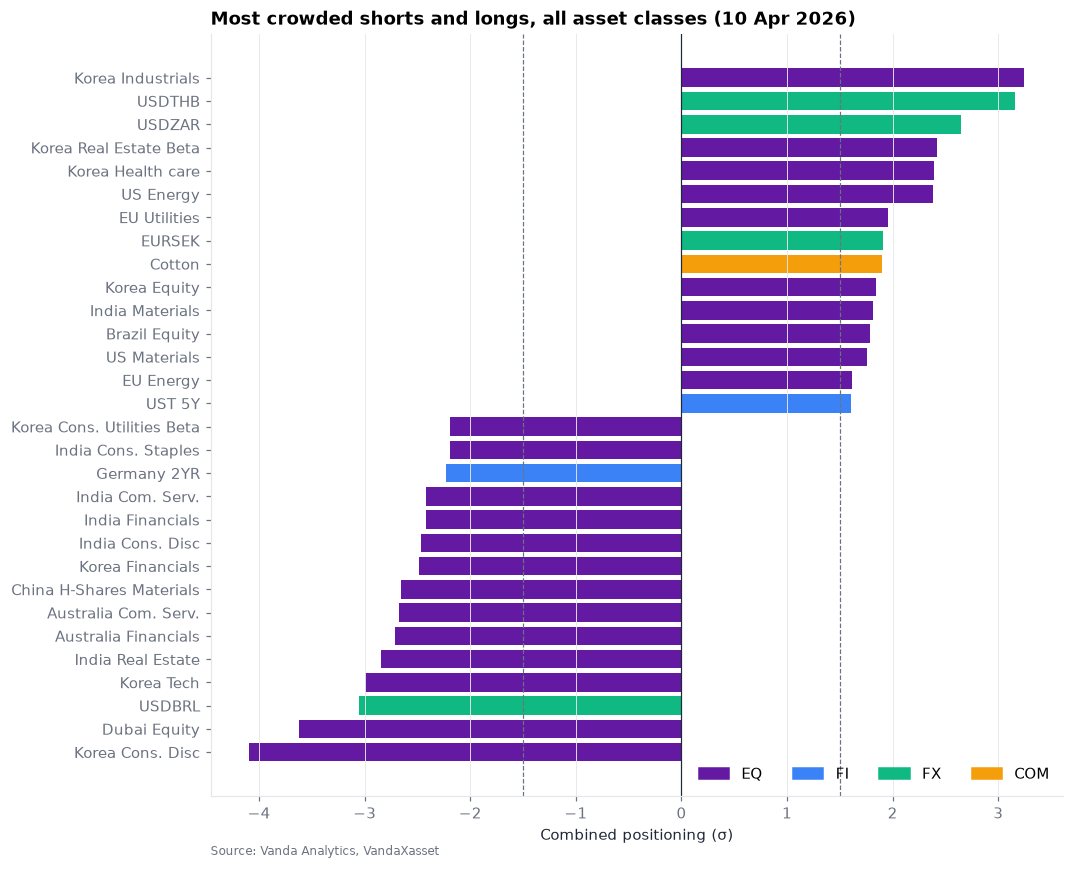

In [4]:
def bar_rank(df: pd.DataFrame, n: int = 15, title: str = "") -> None:
    top = pd.concat([df.nsmallest(n, "z"), df.nlargest(n, "z").iloc[::-1]])
    fig, ax = plt.subplots(figsize=(10, 9))
    ax.barh(top["name"], top["z"], color=top["asset_type"].map(ASSET_COLORS))
    for level in (-qk.CROWDING_THRESHOLD, qk.CROWDING_THRESHOLD):
        ax.axvline(level, color=qk.VANDA["sub"], lw=0.8, ls="--")
    ax.axvline(0, color=qk.VANDA["ink"], lw=0.8)
    ax.set_title(title)
    ax.set_xlabel("Combined positioning (σ)")
    ax.grid(axis="y", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in ASSET_COLORS.values()]
    ax.legend(handles, ASSET_COLORS.keys(), loc="lower right", ncol=4)
    qk.source_note(ax)
    plt.show()


bar_rank(live, title=f"Most crowded shorts and longs, all asset classes ({panel.index.max():%d %b %Y})")

Sector slices dominate a full-universe ranking because there are many of them. Restricting to **headline** markets (no
sector slices) gives the macro view:

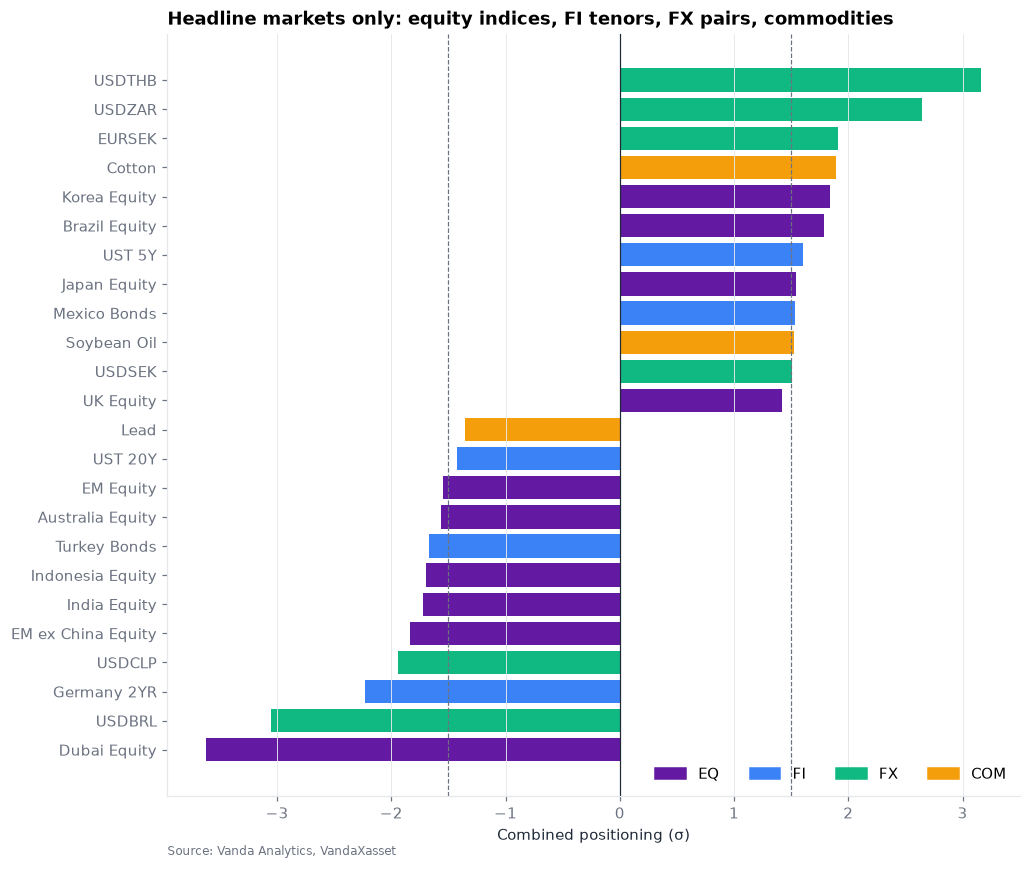

In [5]:
headline = live[live.sector.isna()]
bar_rank(headline, n=12, title="Headline markets only: equity indices, FI tenors, FX pairs, commodities")

In [6]:
cols = ["name", "asset_type", "z", "pct", "chg_4w", "signal", "as_of"]
print("Crowded long")
display(live[live.signal == "crowded_long"].sort_values("z", ascending=False)[cols].round(2))
print("Crowded short")
display(live[live.signal == "crowded_short"].sort_values("z")[cols].round(2))

Crowded long


,name,asset_type,z,pct,chg_4w,signal,as_of
KREQCOMB-INDU,Korea Industrials,EQ,3.25,98.68,-1.29,crowded_long,2026-04-10 00:00:00
THFXCOMB-USDTHB,USDTHB,FX,3.16,99.61,0.73,crowded_long,2026-04-10 00:00:00
ZAFXCOMB-USDZAR,USDZAR,FX,2.65,98.56,-0.03,crowded_long,2026-04-10 00:00:00
KREQCOMB-RLST-BETA,Korea Real Estate Beta,EQ,2.42,99.98,0.45,crowded_long,2026-04-10 00:00:00
KREQCOMB-HLTH,Korea Health care,EQ,2.39,98.64,-0.43,crowded_long,2026-04-10 00:00:00
USEQCOMB-ENER,US Energy,EQ,2.39,96.98,-0.64,crowded_long,2026-04-10 00:00:00
EUEQCOMB-UTIL,EU Utilities,EQ,1.96,97.66,-0.85,crowded_long,2026-04-10 00:00:00
SEFXCOMB-EURSEK,EURSEK,FX,1.91,97.52,1.19,crowded_long,2026-04-10 00:00:00
GLCOMCOMB-CT1,Cotton,COM,1.90,95.25,1.57,crowded_long,2026-04-10 00:00:00
KREQCOMB,Korea Equity,EQ,1.84,85.63,0.19,crowded_long,2026-04-10 00:00:00


Crowded short


,name,asset_type,z,pct,chg_4w,signal,as_of
KREQCOMB-DISC,Korea Cons. Disc,EQ,-4.09,0.02,-0.80,crowded_short,2026-04-10 00:00:00
AEEQCOMB,Dubai Equity,EQ,-3.62,0.01,-3.42,crowded_short,2026-04-10 00:00:00
BRFXCOMB-USDBRL,USDBRL,FX,-3.06,0.24,-1.41,crowded_short,2026-04-10 00:00:00
KREQCOMB-TECH,Korea Tech,EQ,-2.99,0.32,-0.99,crowded_short,2026-04-10 00:00:00
INEQCOMB-RLST,India Real Estate,EQ,-2.84,0.77,-1.53,crowded_short,2026-03-31 00:00:00
AUEQCOMB-FINA,Australia Financials,EQ,-2.71,0.25,-0.77,crowded_short,2026-04-10 00:00:00
AUEQCOMB-COMS,Australia Com. Serv.,EQ,-2.67,1.27,-0.50,crowded_short,2026-04-10 00:00:00
CNEQHSHRCOMB-MATE,China H-Shares Materials,EQ,-2.66,0.01,-1.11,crowded_short,2026-04-10 00:00:00
KREQCOMB-FINA,Korea Financials,EQ,-2.49,0.06,-1.69,crowded_short,2026-04-10 00:00:00
INEQCOMB-DISC,India Cons. Disc,EQ,-2.47,2.00,-1.53,crowded_short,2026-03-31 00:00:00


## 4. Crowding breadth through time

A single crowded market is a trade idea. **Many crowded markets at once** is a regime: positioning-driven reversals
tend to cluster when the whole universe leans the same way. Breadth is the share of series beyond ±1.5σ on each day.
Weekly and monthly series are forward-filled for at most 10 business days so they count between releases.

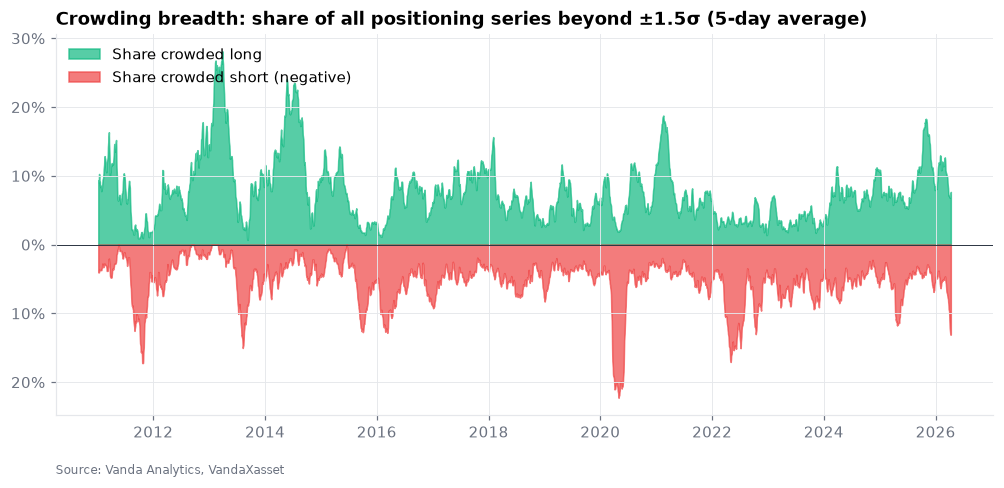

In [7]:
daily = panel.resample("B").last().ffill(limit=10).loc["2011":]
active = daily.notna().sum(axis=1)

breadth = pd.DataFrame({
    "crowded long": (daily > qk.CROWDING_THRESHOLD).sum(axis=1) / active,
    "crowded short": -(daily < -qk.CROWDING_THRESHOLD).sum(axis=1) / active,
}).rolling(5).mean()

fig, ax = plt.subplots()
ax.fill_between(breadth.index, breadth["crowded long"], color=qk.VANDA["pos"], alpha=0.7, label="Share crowded long")
ax.fill_between(breadth.index, breadth["crowded short"], color=qk.VANDA["neg"], alpha=0.7, label="Share crowded short (negative)")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{abs(v):.0%}"))
ax.set_title("Crowding breadth: share of all positioning series beyond ±1.5σ (5-day average)")
ax.legend(loc="upper left")
qk.source_note(ax)
plt.show()

Split by asset class, today versus the past year:

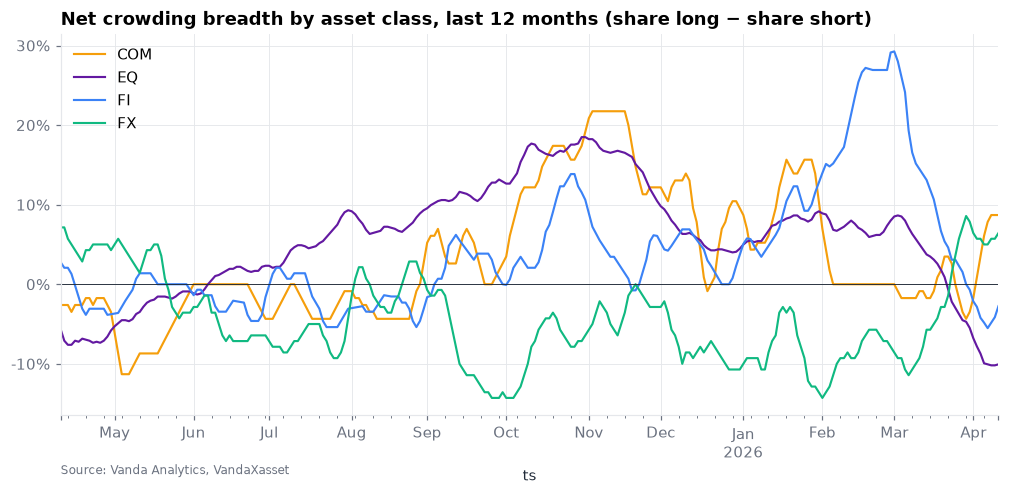

In [8]:
by_asset = {}
for asset, group in meta.groupby("asset_type"):
    sub = daily[group.index.intersection(daily.columns)]
    n = sub.notna().sum(axis=1)
    by_asset[asset] = ((sub > qk.CROWDING_THRESHOLD).sum(axis=1) - (sub < -qk.CROWDING_THRESHOLD).sum(axis=1)) / n

net_breadth = pd.DataFrame(by_asset).rolling(5).mean()
ax = net_breadth.loc[net_breadth.index.max() - pd.Timedelta(days=365):].plot(color=[ASSET_COLORS[c] for c in net_breadth.columns], lw=1.4,
     title="Net crowding breadth by asset class, last 12 months (share long − share short)")
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
qk.source_note(ax)
plt.show()

## 5. Positioning momentum

Level tells you how crowded a trade is; the 4-week change tells you **which way the crowd is moving**. Together they
sort every market into four regimes:

| | Positioning rising | Positioning falling |
|---|---|---|
| **Long (z > 0)** | Building longs | Unwinding longs |
| **Short (z < 0)** | Covering shorts | Building shorts |

The interesting corners are extreme *and* moving: crowded longs starting to unwind, and crowded shorts starting to cover.

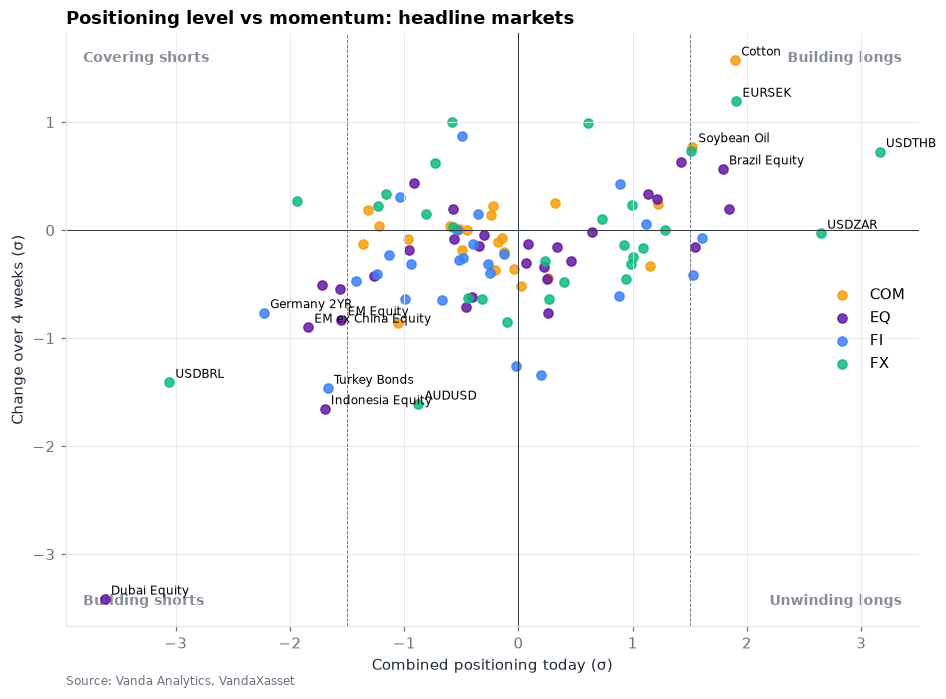

In [9]:
fig, ax = plt.subplots(figsize=(10, 7))
for asset, g in headline.groupby("asset_type"):
    ax.scatter(g.z, g.chg_4w, s=36, color=ASSET_COLORS[asset], label=asset, alpha=0.85)
ax.axhline(0, color=qk.VANDA["ink"], lw=0.6)
ax.axvline(0, color=qk.VANDA["ink"], lw=0.6)
for level in (-qk.CROWDING_THRESHOLD, qk.CROWDING_THRESHOLD):
    ax.axvline(level, color=qk.VANDA["sub"], lw=0.6, ls="--")

notable = headline.assign(score=headline.z.abs() + headline.chg_4w.abs()).nlargest(14, "score")
for label, row in notable.iterrows():
    ax.annotate(row["name"], (row.z, row.chg_4w), fontsize=8, xytext=(4, 3), textcoords="offset points")

for x, y, text in [(0.98, 0.97, "Building longs"), (0.98, 0.03, "Unwinding longs"), (0.02, 0.97, "Covering shorts"), (0.02, 0.03, "Building shorts")]:
    ax.text(x, y, text, transform=ax.transAxes, ha="right" if x > 0.5 else "left", va="top" if y > 0.5 else "bottom", color=qk.VANDA["sub"], fontsize=9, fontweight="bold", zorder=0, alpha=0.8)
ax.set_xlabel("Combined positioning today (σ)")
ax.set_ylabel("Change over 4 weeks (σ)")
ax.set_title("Positioning level vs momentum: headline markets")
ax.legend(loc="center right")
qk.source_note(ax)
plt.show()

In [10]:
def regime(row) -> str:
    if row.z >= 0:
        return "Building longs" if row.chg_4w >= 0 else "Unwinding longs"
    return "Covering shorts" if row.chg_4w >= 0 else "Building shorts"


live = live.assign(regime=live.apply(regime, axis=1))
turning = live[(live.z.abs() >= 1.0) & (np.sign(live.z) != np.sign(live.chg_4w)) & (live.chg_4w.abs() >= 0.5)]
print("Extreme positioning (|z| ≥ 1) now reversing by at least 0.5σ over 4 weeks:")
turning.sort_values("chg_4w")[["name", "asset_type", "z", "chg_4w", "regime"]].round(2)

Extreme positioning (|z| ≥ 1) now reversing by at least 0.5σ over 4 weeks:


,name,asset_type,z,chg_4w,regime
USEQCOMB-MATE,US Materials,EQ,1.76,-1.61,Unwinding longs
INEQCOMB-MATE,India Materials,EQ,1.82,-1.31,Unwinding longs
KREQCOMB-INDU,Korea Industrials,EQ,3.25,-1.29,Unwinding longs
EUEQCOMB-UTIL,EU Utilities,EQ,1.96,-0.85,Unwinding longs
CNEQASHRCOMB-ENER,China A-Shares Energy,EQ,1.20,-0.75,Unwinding longs
USEQCOMB-ENER,US Energy,EQ,2.39,-0.64,Unwinding longs
CNEQASHRCOMB-MATE,China A-Shares Materials,EQ,1.10,-0.52,Unwinding longs


## 6. How headline markets co-move

Correlations of **weekly changes** in positioning show which markets share a crowd. High correlation means the same
investors are probably moving both, so a position in one is partly a position in the other.

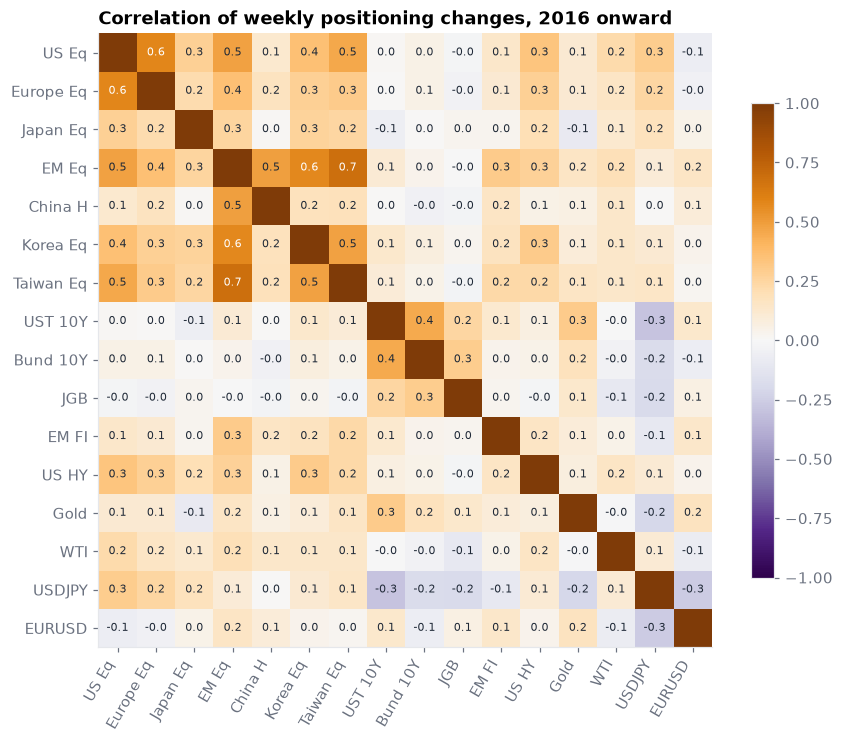

In [11]:
headline_set = {
    "USEQCOMB": "US Eq", "EUEQCOMB": "Europe Eq", "JPEQCOMB": "Japan Eq", "EMEQCOMB": "EM Eq", "CNEQHSHRCOMB": "China H",
    "KREQCOMB": "Korea Eq", "TWEQCOMB": "Taiwan Eq", "USFICOMB-10YR": "UST 10Y", "DEFICOMB-10YR": "Bund 10Y",
    "JPFICOMB": "JGB", "EMFICOMB": "EM FI", "USFICOMB-HY": "US HY", "GLCOMCOMB-GC1": "Gold", "GLCOMCOMB-CL1": "WTI",
    "JPFXCOMB-USDJPY": "USDJPY", "EUFXCOMB-EURUSD": "EURUSD",
}
available = {k: v for k, v in headline_set.items() if k in panel}
weekly_changes = panel[list(available)].resample("W-FRI").last().diff().rename(columns=available).loc["2016":]
corr = weekly_changes.corr()

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(corr, cmap="PuOr_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=60, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for (i, j), v in np.ndenumerate(corr.values):
    if i != j:
        ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.5 else qk.VANDA["ink"])
ax.grid(False)
fig.colorbar(im, shrink=0.7)
ax.set_title("Correlation of weekly positioning changes, 2016 onward")
plt.show()

## 7. Export the screen

In [12]:
out = Path("output")
out.mkdir(exist_ok=True)
export = screen.reset_index().rename(columns={"index": "series_label"})[[
    "series_label", "name", "asset_type", "country", "sector", "as_of", "z", "pct", "chg_4w", "z_1y_min", "z_1y_max", "signal", "stale",
]].sort_values("z")
export.to_csv(out / "crowding_screen.csv", index=False)
print(f"{len(export)} rows → {out / 'crowding_screen.csv'}")

235 rows → output/crowding_screen.csv


**Going live:** swap the S3 panel for `client.positioning.get_latest(series_ids=[...])` (notebook 01). It returns the
level and the `signal` for every series in one call, and refreshes hourly.

---
**Next:** `04 - Restated vs Point-in-Time`: before trading any of this, make sure the backtest only sees what was knowable.